# 09b The runner-up on all products

07h compared eight time-series models on the 150-product sample, and 09 fitted the winner on all 726 products. Here
we fit the runner-up, the contender with the second-lowest median RMSE in 07h, on all 726 products as well, on the
same seven origins. It answers a simple question: does the order of the two hold outside the sample, or was the
winner's lead a feature of those 150 products? The runner-up keeps the setting tuned on the validation dates in 07d
or 07f, and the same blow-up guard as 09. We fit the static version only; the stock work uses the winner.

## Load

In [1]:
import os, sys, time, warnings
sys.path.append("../src")
os.environ["PYTHONPATH"] = os.path.abspath("../src")    # the joblib workers need src/ too
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from config import ROOT, PROCESSED, TABLES, FIGS, ORIGINS, EVAL_ORIGINS, SEED, FIG_STYLE, BEST, BEST_NAME
import ts_models as tm
import best_model as bm
from metrics import paired_test

RERUN = False
N_JOBS = 10
FITS = PROCESSED / "runner_up_fits"
plt.rcParams.update(FIG_STYLE)
written = []

inp = tm.load_inputs(items=None)
daily, sample = inp["daily"], inp["sample"]
item_cat = inp["long_df"].groupby("item_id")["category"].first()
err = pd.read_csv(PROCESSED / "backtest_errors.csv", parse_dates=["origin"])
head = pd.read_csv(TABLES / "ts_headline.csv", index_col="model")
cont = head[head["kind"] == "contender"].sort_values("rmse")
winner, runner = cont.index[0], cont.index[1]
spec = (bm.combination_spec() if runner == "combination" else
        {"model": runner, "name": head.loc[runner, "name"], "members": {runner: bm.spec_of(runner)}})
KEY = {"ets": "ets_boxcox"}.get(runner, runner)       # 07h stores the Box-Cox Holt-Winters as 'ets'
print(f"winner {head.loc[winner, 'name']} (RMSE {cont.iloc[0]['rmse']:.3f}), "
      f"runner-up {head.loc[runner, 'name']} (RMSE {cont.iloc[1]['rmse']:.3f})")
print("its settings:", spec["members"])

winner Combination (RMSE 4.392), runner-up SARIMA (RMSE 4.445)
its settings: {'sarima': {'kind': 'sarima', 'exog': []}}


## Orders, if it needs them

A SARIMA member needs an order for every product: the 07a order for the 150 sample products, and for the other 576
the order 09 searched at the warm-up origin, read from 09's cache.

In [2]:
orders = None
if bm.needs_orders(spec):
    known = {i: (inp["orders"].loc[i, "sarima_order"], inp["orders"].loc[i, "sarima_sorder"]) for i in sample["item_id"]}
    orders = bm.orders_for(daily, ORIGINS[0], PROCESSED / "best_fits", known=known, n_jobs=N_JOBS)
    print(pd.Series({i: f"{v[0]} {v[1]}" for i, v in orders.items()}).value_counts().head(5).to_string())
else:
    print("no SARIMA member, so no orders are needed")

(1, 1, 2) (1, 0, 1, 7)    157
(0, 1, 1) (1, 0, 1, 7)    134
(1, 1, 1) (1, 0, 1, 7)     88
(2, 1, 1) (1, 0, 1, 7)     84
(2, 1, 2) (1, 0, 1, 7)     63


## Fitting it on all 726 products

In [3]:
t0 = time.time()
fc = bm.run_best(daily, ORIGINS, {}, FITS, spec, orders, inp["flags"], inp["prices"], N_JOBS, RERUN)
fc = fc.assign(model=KEY).drop(columns="variant")
print(f"{len(fc):,} rows ({(time.time() - t0) / 60:.1f} min); fell back to seasonal naive in "
      f"{fc.drop_duplicates(['item_id', 'origin'])['fallback'].mean():.2%} of product-origins")

# check: on the sample, the forecast must be the one 07h scored (07h applies the same guard)
ref = pd.read_parquet(TABLES / "ts_forecasts.parquet", filters=[("model", "==", runner)])
chk = fc.merge(ref, on=["item_id", "origin", "date"])
print(f"against 07h on {chk['item_id'].nunique()} sample products and {chk['origin'].nunique()} origins: "
      f"largest difference {float((chk['forecast_x'] - chk['forecast_y']).abs().max()):.2e}")
assert (chk["forecast_x"] - chk["forecast_y"]).abs().max() < 1e-6, "these are not the forecasts 07h scored"
fc.to_parquet(PROCESSED / "runner_up_forecasts.parquet", index=False)
written.append(PROCESSED / "runner_up_forecasts.parquet")

142,296 rows (0.0 min); fell back to seasonal naive in 0.08% of product-origins
against 07h on 150 sample products and 7 origins: largest difference 0.00e+00


## Scores, the same way as 09

Per product and origin: MAE, RMSE, and MASE with the same scale as 09 (the in-sample error of seasonal naive on all
history up to the origin). The winner and seasonal naive come from 09's file, static versions.

In [4]:
f = fc.merge(inp["actuals"], on=["item_id", "date"])
f["category"] = f["item_id"].map(item_cat)
sc = (f.assign(abs_err=(f["actual"] - f["forecast"]).abs(), sq_err=(f["actual"] - f["forecast"]) ** 2)
       .groupby(["item_id", "category", "origin", "model"], as_index=False).agg(mae=("abs_err", "mean"), mse=("sq_err", "mean")))
sc["rmse"] = np.sqrt(sc["mse"])
scale = err[["item_id", "origin", "mase_scale"]].drop_duplicates(["item_id", "origin"])
sc = sc.merge(scale, on=["item_id", "origin"])
sc["mase"] = sc["mae"] / sc["mase_scale"]
others = err[(err["variant"] == "static") & err["model"].isin(["seasonal_naive", BEST])]
scores = pd.concat([sc, others], ignore_index=True)[["item_id", "category", "origin", "model", "mae", "rmse", "mase"]]
scores = scores[scores["origin"].isin(EVAL_ORIGINS)]
scores.to_csv(TABLES / "runner_up_726_scores.csv", index=False)
written.append(TABLES / "runner_up_726_scores.csv")

per_item = scores.groupby(["item_id", "category", "model"], as_index=False)[["mase", "rmse", "mae"]].mean()
med = per_item.groupby("model")[["mase", "rmse", "mae"]].median()
med["products"] = per_item.groupby("model")["item_id"].nunique()
SHOW = ["seasonal_naive", BEST, KEY]
print("median over products of each product's mean over the six scored origins:")
print(med.loc[SHOW].round(4).to_string())
print("\nmedian MASE by category:")
print(per_item.pivot_table(index="category", columns="model", values="mase", aggfunc="median")[SHOW].round(4).to_string())

median over products of each product's mean over the six scored origins:
                  mase    rmse     mae  products
model                                           
seasonal_naive  0.9756  6.3243  4.9167       726
best            0.7467  4.8376  3.7948       726
sarima          0.7546  4.8243  3.8197       726

median MASE by category:
model      seasonal_naive    best  sarima
category                                 
FOODS              0.9565  0.7611  0.7682
HOBBIES            1.0044  0.7488  0.7561
HOUSEHOLD          0.9781  0.7396  0.7444


## Does the winner stay ahead on all products?

Paired Wilcoxon tests on each product's mean scored error, the runner-up minus the other model, with a bootstrap
interval for the median difference. Negative means the runner-up has the smaller error.

In [5]:
rows = []
for metric in ["mase", "rmse", "mae"]:
    wide = per_item.pivot_table(index=["item_id", "category"], columns="model", values=metric).reset_index()
    for other in [BEST, "seasonal_naive"]:
        for cat in ["ALL", "FOODS", "HOBBIES", "HOUSEHOLD"]:
            d = wide if cat == "ALL" else wide[wide["category"] == cat]
            rows.append({"metric": metric, "comparison": f"{KEY} - {other}", "category": cat,
                         **paired_test(d[KEY] - d[other], seed=SEED)})
tests = pd.DataFrame(rows)
tests.to_csv(TABLES / "runner_up_726_tests.csv", index=False)
written.append(TABLES / "runner_up_726_tests.csv")
cols = ["metric", "comparison", "category", "n", "median_diff", "ci_low", "ci_high", "share_improved", "p_value"]
print(tests[tests["category"] == "ALL"][cols].round(4).to_string(index=False))
print()
print(tests[(tests["metric"] == "mase") & (tests["category"] != "ALL")][cols].round(4).to_string(index=False))

metric              comparison category   n  median_diff  ci_low  ci_high  share_improved  p_value
  mase           sarima - best      ALL 726       0.0074  0.0056   0.0093          0.3540      0.0
  mase sarima - seasonal_naive      ALL 726      -0.2082 -0.2172  -0.1991          0.9669      0.0
  rmse           sarima - best      ALL 726       0.0201  0.0149   0.0255          0.3760      0.0
  rmse sarima - seasonal_naive      ALL 726      -1.2892 -1.3610  -1.2109          0.9738      0.0
   mae           sarima - best      ALL 726       0.0302  0.0215   0.0383          0.3526      0.0
   mae sarima - seasonal_naive      ALL 726      -0.9709 -1.0337  -0.9103          0.9656      0.0

metric              comparison  category   n  median_diff  ci_low  ci_high  share_improved  p_value
  mase           sarima - best     FOODS 337       0.0065  0.0020   0.0103          0.4184   0.0014
  mase           sarima - best   HOBBIES 106       0.0084  0.0065   0.0113          0.1981   0.0000
  mase

pooled bias (total forecast / total sales - 1):
model
best      -1.57%
sarima    -0.36%


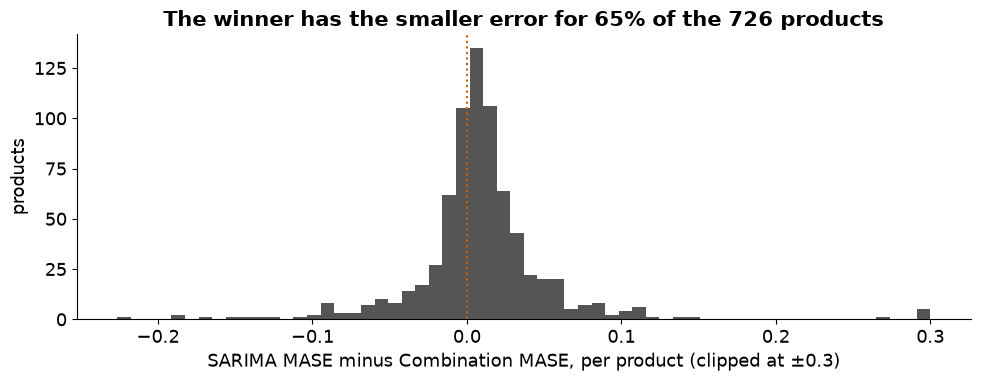

In [6]:
e = pd.concat([f[["item_id", "origin", "date", "model", "forecast", "actual"]],
               pd.read_parquet(PROCESSED / "backtest_forecasts.parquet",
                               filters=[("variant", "==", "static"), ("model", "in", [BEST])])
               [["item_id", "origin", "date", "model", "forecast", "actual"]]])
e = e[e["origin"].isin(EVAL_ORIGINS)]
bias = e.groupby("model").apply(lambda g: g["forecast"].sum() / g["actual"].sum() - 1, include_groups=False)
print("pooled bias (total forecast / total sales - 1):")
print(bias.map("{:+.2%}".format).to_string())

wide = per_item.pivot(index="item_id", columns="model", values="mase")
d = (wide[KEY] - wide[BEST]).clip(-0.3, 0.3)
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(d, bins=60, color="#555555")
ax.axvline(0, color="#D55E00", ls=":")
ax.set_xlabel(f"{head.loc[runner, 'name']} MASE minus {BEST_NAME.split(' (')[0]} MASE, per product (clipped at ±0.3)")
ax.set_ylabel("products")
ax.set_title(f"The winner has the smaller error for {(d > 0).mean():.0%} of the 726 products")
fig.tight_layout()
fig.savefig(FIGS / "runner_up_vs_best_726.png")
written.append(FIGS / "runner_up_vs_best_726.png")
plt.show()

## What we found

On all 726 products the winner stays ahead of the runner-up. Product by product, SARIMA has the larger error on all
three measures: a median difference of +0.0074 MASE (95% interval +0.0056 to +0.0093), +0.020 RMSE and +0.030 MAE,
each with p < 0.001, and SARIMA is better on only 35-38% of products. The same holds in every category (MASE +0.0065
in FOODS, +0.0084 in HOBBIES, +0.0070 in HOUSEHOLD, all p < 0.01).

The medians alone tell a slightly different story on RMSE. SARIMA's median (4.824) is a little below the
combination's (4.838), because the two medians fall on different products. The paired test compares each product with
itself, so it is the one to read.

SARIMA is still far ahead of seasonal naive: its MASE is lower by 0.208 per product, and it wins on 97% of products.
Both models forecast a little low in total, the combination by 1.6% and SARIMA by 0.4%. The order from the 150-product
sample holds on all products, so the stock work keeps the combination.

## What comes next

`10_model_comparison` puts the runner-up next to the winner and seasonal naive in the table for all 726 products.

In [7]:
# files this notebook wrote
for p in written:
    print(p.relative_to(ROOT), f"{p.stat().st_size / 1e3:,.0f} KB")

data\processed\runner_up_forecasts.parquet 1,408 KB
outputs\tables\runner_up_726_scores.csv 1,273 KB
outputs\tables\runner_up_726_tests.csv 4 KB
outputs\figures\runner_up_vs_best_726.png 42 KB
